# Machine Failure Detection Using Machine Learning and Deep Learning
### Main Project — Predictive Maintenance (AI4I 2020)

**Objective:** Predict `Machine failure` (0/1) using machine operating measurements, identify influential factors, and demonstrate prediction on a new reading.

**Dataset:** UCI AI4I 2020 Predictive Maintenance Dataset (10,000 rows, 14 original columns). [UCI dataset page](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset).

**Important:** This is a **classification** problem, so **R² is not applicable**. Evaluate precision, recall, F1, ROC-AUC and average precision (PR-AUC). The dataset is synthetic and machine failures are rare; accuracy alone can mislead.

**Integrity:** We exclude `TWF`, `HDF`, `PWF`, `OSF`, and `RNF` (failure-mode outcomes), as well as identifier columns, to avoid leakage. Model selection and threshold tuning use training/validation data only. The test set is reserved for final reporting.
**Model note:** This notebook uses traditional `GradientBoostingClassifier`, not histogram-based gradient boosting. The final model is chosen between tuned Gradient Boosting and Random Forest using training-fold cross-validation.


## 1. Install required packages
Run once for your selected Jupyter kernel; restart the kernel if prompted.

**Deep learning:** TensorFlow/Keras is also required. Use a TensorFlow-compatible Python environment (Python 3.11 or 3.12 is a safe choice). Restart the kernel after installing if necessary.

In [2]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn joblib requests tensorflow

Note: you may need to restart the kernel to use updated packages.


## 2. Imports and reproducibility

In [3]:
import os, io, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import joblib
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve)
from sklearn.inspection import permutation_importance
RANDOM_STATE = 42
sns.set_theme(style='whitegrid')
print('Libraries imported successfully')

Libraries imported successfully


## 3. Load the dataset

**Preferred:** Download the CSV from the UCI page and place `ai4i2020.csv` beside this notebook. If it is not present, the cell attempts to fetch it from the UCI archive. An internet connection is needed for the first download.

In [4]:
local_candidates = [Path('ai4i2020.csv'), Path('AI4I_2020.csv'), Path('ai4i+2020+predictive+maintenance+dataset.csv')]
existing = next((p for p in local_candidates if p.exists()), None)
if existing:
    df = pd.read_csv(existing)
    print('Loaded local file:', existing)
else:
    urls = [
        'https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip',
        'https://archive.ics.uci.edu/ml/machine-learning-databases/00601/ai4i2020.csv',
    ]
    df = None
    errors = []
    for url in urls:
        try:
            response = requests.get(url, timeout=30)
            response.raise_for_status()
            if response.content[:2] == b'PK':
                with zipfile.ZipFile(io.BytesIO(response.content)) as z:
                    matches = [name for name in z.namelist() if name.lower().endswith('.csv')]
                    if not matches: raise ValueError('No CSV found in archive')
                    df = pd.read_csv(z.open(matches[0]))
            else:
                df = pd.read_csv(io.BytesIO(response.content))
            df.to_csv('ai4i2020.csv', index=False)
            print('Downloaded and saved ai4i2020.csv')
            break
        except Exception as e:
            errors.append(f'{url}: {e}')
    if df is None:
        raise FileNotFoundError('Could not load dataset. Download ai4i2020.csv from the UCI dataset page and place it beside this notebook.\n' + '\n'.join(errors))
print('Shape:', df.shape)
display(df.head(10))

Loaded local file: ai4i2020.csv
Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
5,6,M14865,M,298.1,308.6,1425,41.9,11,0,0,0,0,0,0
6,7,L47186,L,298.1,308.6,1558,42.4,14,0,0,0,0,0,0
7,8,L47187,L,298.1,308.6,1527,40.2,16,0,0,0,0,0,0
8,9,M14868,M,298.3,308.7,1667,28.6,18,0,0,0,0,0,0
9,10,M14869,M,298.5,309.0,1741,28.0,21,0,0,0,0,0,0


## 4. Dataset inspection and quality checks

In [5]:
print('Columns:', df.columns.tolist())
print('Shape:', df.shape)
df.info()
print('\nMissing values:')
display(df.isna().sum().to_frame('Missing'))
print('\nDuplicate rows:', df.duplicated().sum())
display(df.describe(include='all').T)
assert 'Machine failure' in df.columns, 'Expected target Machine failure not found' 

Columns: ['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
Shape: (10000, 14)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      100

,Missing
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0



Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
Product ID,10000,10000,M14860,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
TWF,10000.0,NaN,NaN,NaN,0.0046,0.067671,0.0,0.0,0.0,0.0,1.0


## 5. Target distribution and class imbalance

Machine failure
0    9661
1     339
Name: count, dtype: int64
Failure prevalence: 3.39%


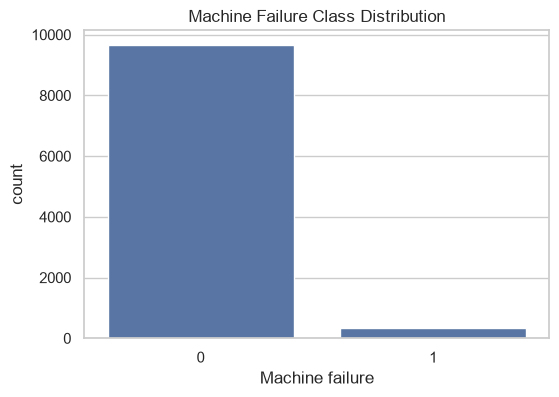

In [6]:
target = 'Machine failure'
print(df[target].value_counts(dropna=False))
print('Failure prevalence:', f'{df[target].mean():.2%}')
fig, ax = plt.subplots(figsize=(6,4))
sns.countplot(data=df, x=target, ax=ax)
ax.set_title('Machine Failure Class Distribution')
plt.show()

## 6. Exploratory data analysis

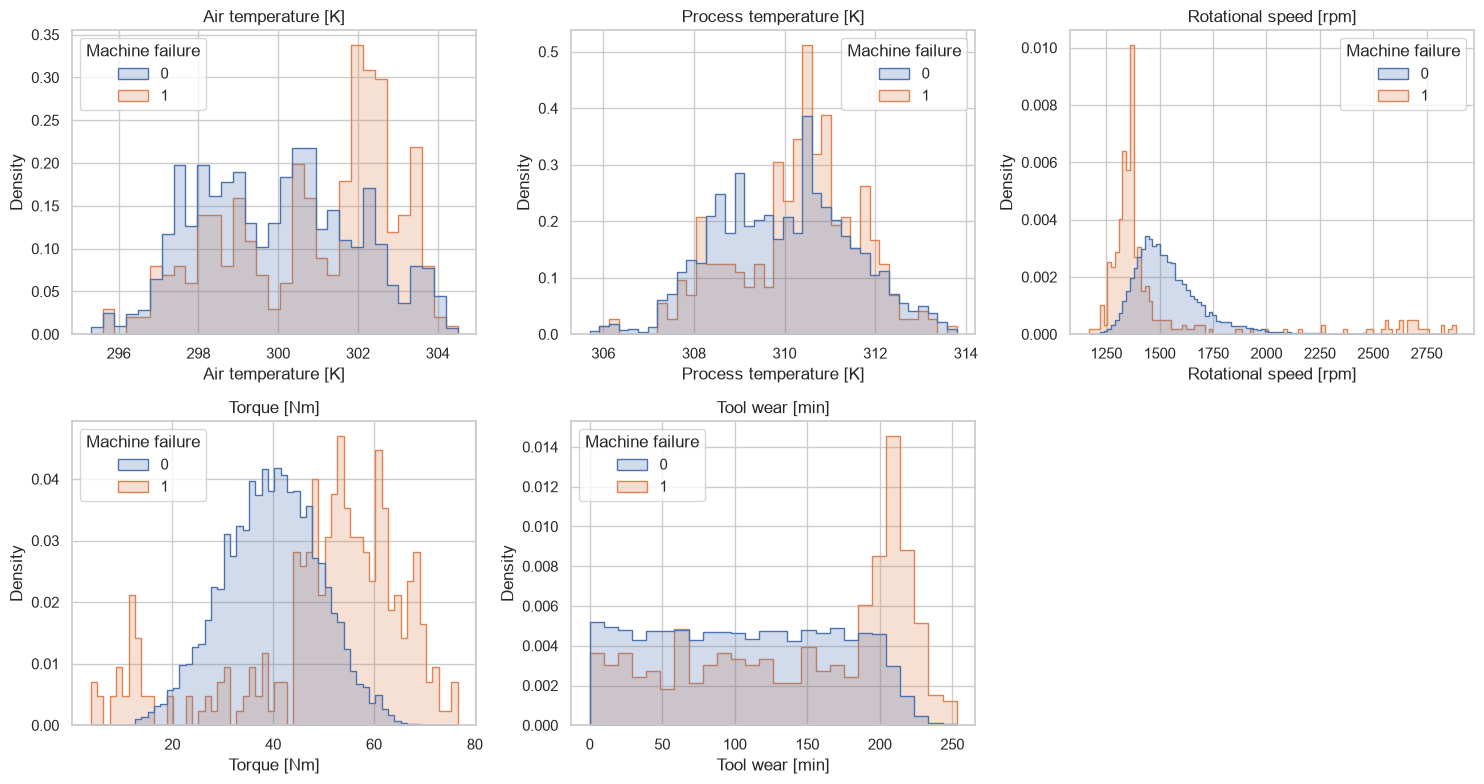

Machine failure,0,1
Type,,
H,0.979,0.021
L,0.961,0.039
M,0.972,0.028


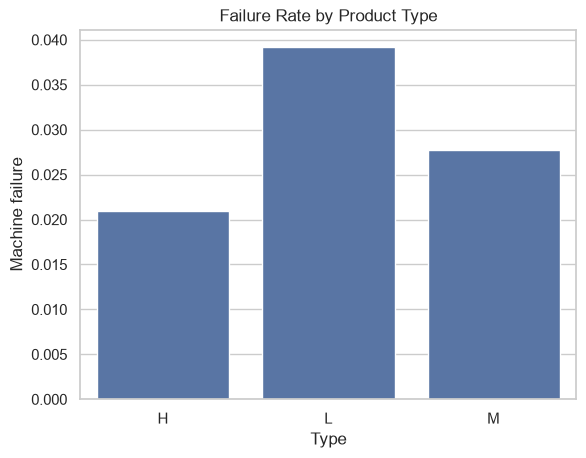

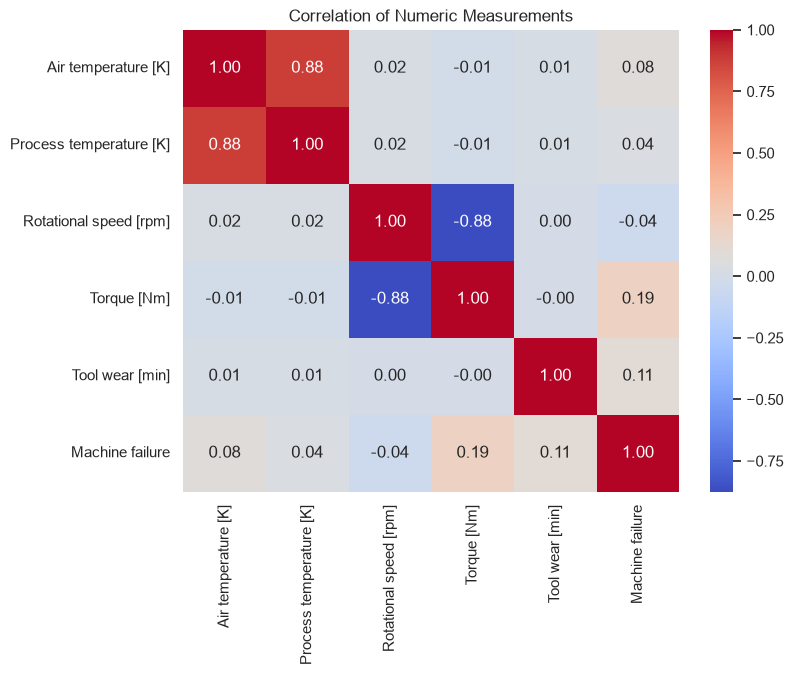

In [7]:
numeric_eda = [c for c in ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]'] if c in df.columns]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, numeric_eda):
    sns.histplot(data=df, x=c, hue=target, stat='density', common_norm=False, element='step', ax=ax)
    ax.set_title(c)
for ax in axes.flat[len(numeric_eda):]: ax.axis('off')
plt.tight_layout(); plt.show()
if 'Type' in df.columns:
    display(pd.crosstab(df['Type'], df[target], normalize='index').round(3))
    sns.barplot(data=df.groupby('Type', as_index=False)[target].mean(), x='Type', y=target)
    plt.title('Failure Rate by Product Type'); plt.show()
plt.figure(figsize=(8,6))
sns.heatmap(df[numeric_eda + [target]].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation of Numeric Measurements'); plt.show()

## 7. Feature selection and engineering — avoid target leakage

The columns `TWF`, `HDF`, `PWF`, `OSF`, `RNF` encode failure outcomes, not independent predictors. Exclude them. `UDI` and `Product ID` are identifiers. We add two physically interpretable engineered measurements.

In [8]:
LEAKAGE_COLUMNS = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
IDENTIFIER_COLUMNS = ['UDI', 'Product ID']
EXCLUDED = [target] + LEAKAGE_COLUMNS + IDENTIFIER_COLUMNS
features = [c for c in df.columns if c not in EXCLUDED]
X = df[features].copy()
y = df[target].astype(int).copy()
def add_features(frame):
    out = frame.copy()
    if {'Process temperature [K]', 'Air temperature [K]'}.issubset(out.columns):
        out['Temperature difference [K]'] = out['Process temperature [K]'] - out['Air temperature [K]']
    if {'Torque [Nm]', 'Rotational speed [rpm]'}.issubset(out.columns):
        out['Mechanical power proxy'] = out['Torque [Nm]'] * out['Rotational speed [rpm]']
    return out
X = add_features(X)
print('Predictor columns:', X.columns.tolist())
assert not set(LEAKAGE_COLUMNS + IDENTIFIER_COLUMNS).intersection(X.columns)
assert y.nunique() == 2
print('X shape:', X.shape)

Predictor columns: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temperature difference [K]', 'Mechanical power proxy']
X shape: (10000, 8)


## 8. Stratified train / validation / test split (70% / 15% / 15%)

In [9]:
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.15, random_state=RANDOM_STATE, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.15/0.85, random_state=RANDOM_STATE, stratify=y_dev)
for name, yy in [('Train',y_train),('Validation',y_val),('Test',y_test)]:
    print(f'{name}: {len(yy)} rows; failures={yy.sum()} ({yy.mean():.2%})')

Train: 7000 rows; failures=237 (3.39%)
Validation: 1500 rows; failures=51 (3.40%)
Test: 1500 rows; failures=51 (3.40%)


## 9. Preprocessing pipeline (fit only on training folds)

In [10]:
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
preprocess = ColumnTransformer([
    ('numeric', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num_cols),
    ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                              ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat_cols)
])
def make_pipeline(clf):
    return Pipeline([('preprocess', preprocess), ('classifier', clf)])
print('Numeric:', num_cols)
print('Categorical:', cat_cols)

Numeric: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temperature difference [K]', 'Mechanical power proxy']
Categorical: ['Type']


## 10. Cross-validated model comparison

Use **stratified five-fold cross-validation on training data**. F1 and average precision are particularly important because failures are rare. The dummy classifier gives a baseline.

In [11]:
models = {
    'Dummy baseline': DummyClassifier(strategy='prior'),
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, min_samples_leaf=8, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight='balanced_subsample', random_state=RANDOM_STATE, n_jobs=-1),
    'Extra Trees': ExtraTreesClassifier(n_estimators=200, min_samples_leaf=2, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE)
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, classifier in models.items():
    pipe = make_pipeline(classifier)
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
        scoring={'f1':'f1', 'roc_auc':'roc_auc', 'pr_auc':'average_precision', 'recall':'recall'}, n_jobs=1)
    rows.append({'Model':name, **{metric: scores[f'test_{metric}'].mean() for metric in ['f1','roc_auc','pr_auc','recall']}})
results = pd.DataFrame(rows).sort_values('pr_auc', ascending=False).reset_index(drop=True)
display(results.round(4))
# results.to_csv('machine_failure_cv_comparison.csv', index=False)  # Optional export disabled
print('Random PR-AUC baseline approximately:', round(y_train.mean(),4))

,Model,f1,roc_auc,pr_auc,recall
0,Gradient Boosting,0.8330,0.9868,0.8760,0.7550
1,Random Forest,0.7987,0.9780,0.8666,0.6916
2,Decision Tree,0.5578,0.9331,0.8011,0.9069
3,Extra Trees,0.7277,0.9697,0.7836,0.7212
4,Logistic Regression,0.2819,0.9268,0.4959,0.8435
5,Dummy baseline,0.0000,0.5000,0.0339,0.0000


Random PR-AUC baseline approximately: 0.0339


## 11. Compare cross-validation scores visually

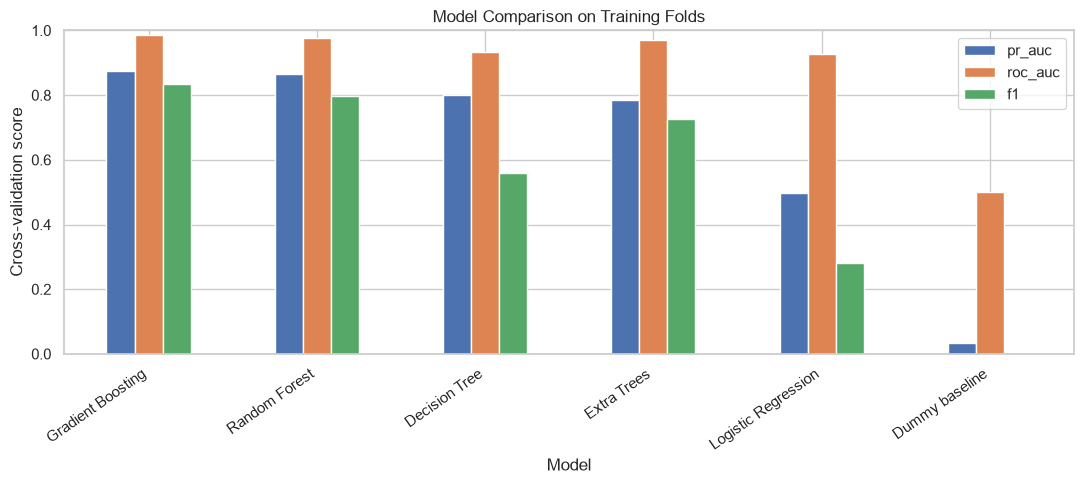

In [12]:
ax = results.set_index('Model')[['pr_auc','roc_auc','f1']].plot(kind='bar', figsize=(11,5), ylim=(0,1))
ax.set_ylabel('Cross-validation score'); ax.set_title('Model Comparison on Training Folds')
plt.xticks(rotation=35, ha='right'); plt.tight_layout(); plt.show()

## 12. Hyperparameter tuning — training data only

We tune Random Forest and Gradient Boosting using randomized search and **average precision**. This may take several minutes. No test-set data is used.

In [13]:
search_spaces = {
    'Random Forest': (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, class_weight='balanced_subsample'),
        {'classifier__n_estimators':[150,250,350], 'classifier__max_depth':[5,10,None],
         'classifier__min_samples_leaf':[1,2,5,10], 'classifier__max_features':['sqrt',0.8]}
    ),
    'Gradient Boosting': (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {'classifier__n_estimators':[100,150,200,250], 'classifier__learning_rate':[0.03,0.07,0.1],
         'classifier__max_depth':[2,3,4], 'classifier__min_samples_leaf':[1,5,10]}
    )
}
search_results = {}
for name,(clf,params) in search_spaces.items():
    print('Tuning:', name)
    search = RandomizedSearchCV(make_pipeline(clf), params, n_iter=12, scoring='average_precision',
        cv=cv, random_state=RANDOM_STATE, n_jobs=1, refit=True)
    search.fit(X_train,y_train)
    search_results[name] = search
    print('Best CV PR-AUC:', round(search.best_score_,4))
    print('Best parameters:', search.best_params_)


Tuning: Random Forest
Best CV PR-AUC: 0.8709
Best parameters: {'classifier__n_estimators': 350, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 0.8, 'classifier__max_depth': None}
Tuning: Gradient Boosting
Best CV PR-AUC: 0.9054
Best parameters: {'classifier__n_estimators': 200, 'classifier__min_samples_leaf': 5, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.03}


## 13. Choose best tuned model using cross-validation, then tune decision threshold on validation

We select the better of the two tuned algorithms based **only on training-fold CV PR-AUC**. Then choose a classification threshold that maximizes F1 on the separate validation set. This threshold is not optimized on the test set.

Selected model: Gradient Boosting
Threshold (validation only): 0.2045
Validation F1: 0.8163
Validation ROC-AUC: 0.9477
Validation PR-AUC: 0.838


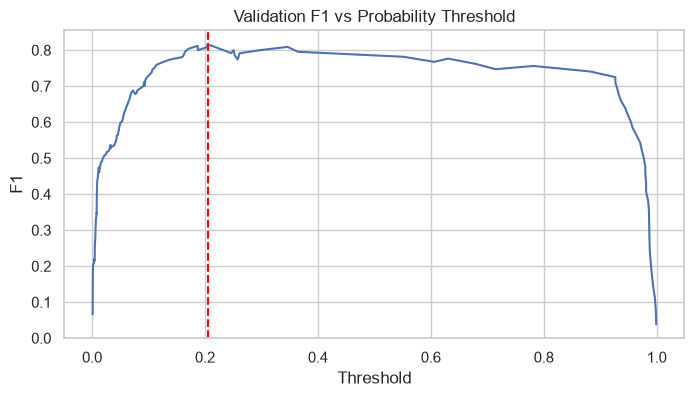

In [14]:
best_name = max(search_results, key=lambda name: search_results[name].best_score_)
best_model = search_results[best_name].best_estimator_
val_prob = best_model.predict_proba(X_val)[:,1]
precision, recall, thresholds = precision_recall_curve(y_val, val_prob)
f1_values = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
best_index = int(np.argmax(f1_values))
threshold = float(thresholds[best_index])
print('Selected model:', best_name)
print('Threshold (validation only):', round(threshold,4))
print('Validation F1:', round(float(f1_values[best_index]),4))
print('Validation ROC-AUC:', round(roc_auc_score(y_val,val_prob),4))
print('Validation PR-AUC:', round(average_precision_score(y_val,val_prob),4))
plt.figure(figsize=(8,4)); plt.plot(thresholds, f1_values); plt.axvline(threshold, color='red', linestyle='--')
plt.title('Validation F1 vs Probability Threshold'); plt.xlabel('Threshold'); plt.ylabel('F1'); plt.show()

## 14. Final held-out test evaluation — once

This is the unbiased final test evaluation of the selected model and validation-derived threshold. Report these actual numbers in the project report; do not change the threshold based on test results.

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Gradient Boosting,0.99,0.8333,0.8824,0.8571,0.9754,0.9207


              precision    recall  f1-score   support

           0       1.00      0.99      0.99      1449
           1       0.83      0.88      0.86        51

    accuracy                           0.99      1500
   macro avg       0.91      0.94      0.93      1500
weighted avg       0.99      0.99      0.99      1500

Confusion matrix (true rows, predicted columns):


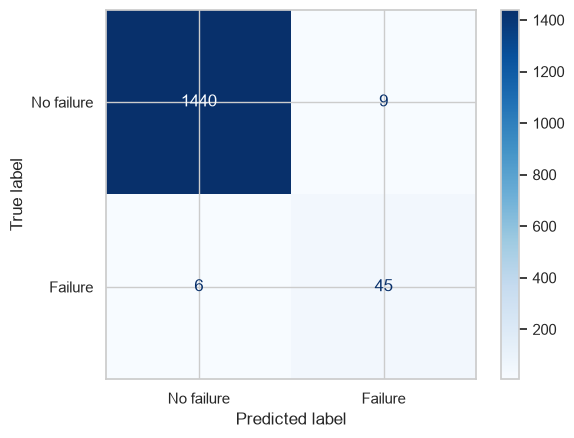

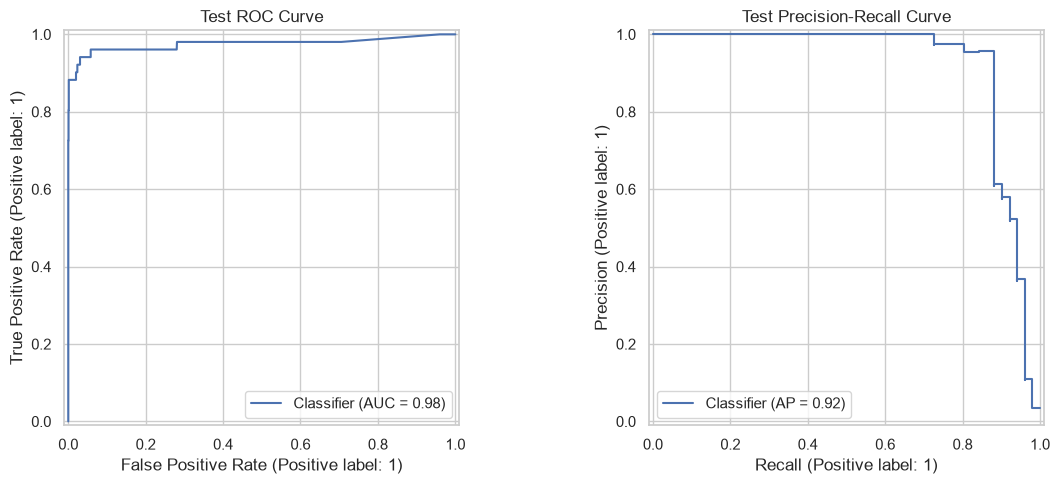

In [15]:
test_prob = best_model.predict_proba(X_test)[:,1]
test_pred = (test_prob >= threshold).astype(int)
final_metrics = {
    'Accuracy': accuracy_score(y_test,test_pred),
    'Precision': precision_score(y_test,test_pred,zero_division=0),
    'Recall': recall_score(y_test,test_pred,zero_division=0),
    'F1': f1_score(y_test,test_pred,zero_division=0),
    'ROC-AUC': roc_auc_score(y_test,test_prob),
    'PR-AUC': average_precision_score(y_test,test_prob)
}
display(pd.DataFrame([final_metrics],index=[best_name]).round(4))
print(classification_report(y_test,test_pred,zero_division=0))
print('Confusion matrix (true rows, predicted columns):')
ConfusionMatrixDisplay.from_predictions(y_test,test_pred,display_labels=['No failure','Failure'],cmap='Blues')
plt.show()
fig, axes = plt.subplots(1,2,figsize=(12,5))
RocCurveDisplay.from_predictions(y_test,test_prob,ax=axes[0]); axes[0].set_title('Test ROC Curve')
PrecisionRecallDisplay.from_predictions(y_test,test_prob,ax=axes[1]); axes[1].set_title('Test Precision-Recall Curve')
plt.tight_layout(); plt.show()
# pd.DataFrame([final_metrics]).to_csv('machine_failure_final_test_metrics.csv', index=False)  # Optional export disabled

## 15. Feature importance (validation permutation importance)

Permutation importance measures the reduction in average precision when one input feature is shuffled on the validation set. This does not imply causation.

,Feature,Mean importance,Std
7,Mechanical power proxy,0.4357,0.0084
5,Tool wear [min],0.3398,0.0528
3,Rotational speed [rpm],0.2593,0.0223
6,Temperature difference [K],0.2281,0.0241
4,Torque [Nm],0.0523,0.0138
0,Type,0.0125,0.0109
2,Process temperature [K],0.0016,0.0034
1,Air temperature [K],0.0003,0.0009


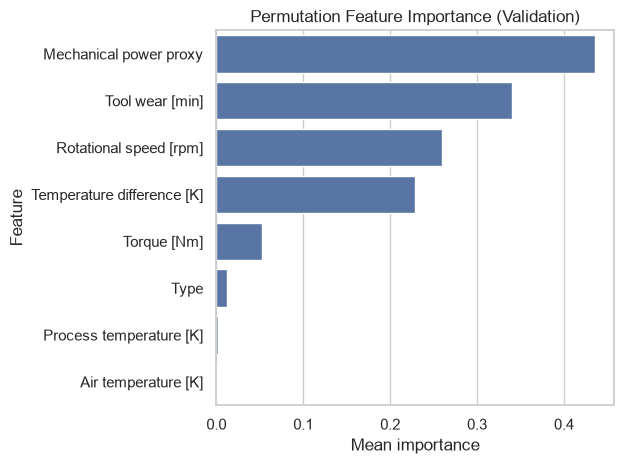

In [16]:
importance = permutation_importance(best_model, X_val, y_val, scoring='average_precision',
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
importance_df = pd.DataFrame({'Feature':X_val.columns,'Mean importance':importance.importances_mean,
                              'Std':importance.importances_std}).sort_values('Mean importance',ascending=False)
display(importance_df.round(4))
sns.barplot(data=importance_df.head(12), y='Feature', x='Mean importance')
plt.title('Permutation Feature Importance (Validation)'); plt.tight_layout(); plt.show()

**Feature Importance Interpretation**

Permutation feature importance analysis indicates that mechanical power proxy has the highest influence on model performance, followed by tool wear, rotational speed, and temperature difference. These results suggest that mechanical operating conditions and equipment wear are important factors for predicting machine failure in the dataset.

The importance values describe the model's reliance on these features and should not be interpreted as evidence of causation.

## 16. Predict a new machine reading

Use the **original feature names**; derived features are calculated with the same function used during training. The example below is illustrative, not a guarantee of a machine's actual condition.

In [17]:
new_reading = {
    'Type': 'M',
    'Air temperature [K]': 300.0,
    'Process temperature [K]': 310.0,
    'Rotational speed [rpm]': 1500,
    'Torque [Nm]': 40.0,
    'Tool wear [min]': 120
}
new_df = add_features(pd.DataFrame([new_reading]))
new_df = new_df.reindex(columns=X.columns)
new_probability = float(best_model.predict_proba(new_df)[:,1][0])
new_prediction = int(new_probability >= threshold)
print('Predicted failure probability:', f'{new_probability:.2%}')
print('Predicted class:', 'Failure' if new_prediction else 'No failure')

Predicted failure probability: 0.10%
Predicted class: No failure


## 17. Save model and prediction configuration

In [18]:
artifact = {'model':best_model, 'threshold':threshold, 'feature_columns':X.columns.tolist(),
            'selected_model':best_name, 'metrics':final_metrics}
joblib.dump(artifact,'machine_failure_detection_model.joblib')
print('Saved machine_failure_detection_model.joblib')

Saved machine_failure_detection_model.joblib


## 18. Deep Learning — Artificial Neural Network (ANN)

An ANN is trained on **the same stratified training, validation, and test partitions** as the ML models. The preprocessing is fitted **only on training data**. This is a genuine deep learning model with multiple hidden Dense layers, not a decision-tree ensemble.

We use class weights because machine failures are rare. We choose the ANN probability threshold using **validation data only**; the test set is used once for the final comparison. The existing Gradient Boosting/Random Forest model artifact remains the Streamlit app model.

In [19]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight

tf.keras.utils.set_random_seed(RANDOM_STATE)

# Fit a fresh preprocessing transformer on training data only.
from sklearn.base import clone
ann_preprocess = clone(preprocess)
X_train_ann = ann_preprocess.fit_transform(X_train)
X_val_ann = ann_preprocess.transform(X_val)
X_test_ann = ann_preprocess.transform(X_test)

# OneHotEncoder can produce sparse matrices; Dense networks require dense arrays.
def to_dense_float32(matrix):
    if hasattr(matrix, 'toarray'):
        matrix = matrix.toarray()
    return np.asarray(matrix, dtype=np.float32)

X_train_ann = to_dense_float32(X_train_ann)
X_val_ann = to_dense_float32(X_val_ann)
X_test_ann = to_dense_float32(X_test_ann)
y_train_ann = y_train.to_numpy(dtype=np.float32)
y_val_ann = y_val.to_numpy(dtype=np.float32)

classes = np.unique(y_train.to_numpy())
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train.to_numpy())
class_weights = {int(cls): float(weight) for cls, weight in zip(classes, weights)}
print('ANN input features:', X_train_ann.shape[1])
print('Class weights:', class_weights)

ANN input features: 10
Class weights: {0: 0.5175218098477007, 1: 14.767932489451477}


### 18.1 Build and train the ANN

Two hidden layers use ReLU, Batch Normalization and Dropout to reduce overfitting. The final sigmoid neuron estimates the probability of machine failure. Early stopping restores the weights from the best validation-loss epoch.

In [20]:
ann_model = keras.Sequential([
    layers.Input(shape=(X_train_ann.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.25),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.20),
    layers.Dense(1, activation='sigmoid')
], name='Machine_Failure_ANN')

ann_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=[keras.metrics.BinaryAccuracy(name='accuracy'),
             keras.metrics.AUC(name='roc_auc'),
             keras.metrics.AUC(name='pr_auc', curve='PR')]
)
ann_model.summary()

history = ann_model.fit(
    X_train_ann, y_train_ann,
    validation_data=(X_val_ann, y_val_ann),
    epochs=80,
    batch_size=64,
    class_weight=class_weights,
    callbacks=[keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=12, restore_best_weights=True
    )],
    verbose=1
)

Model: "Machine_Failure_ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,073 (12.00 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 128 (512.00 B)

Epoch 1/80
110/110 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.7000 - loss: 0.5958 - pr_auc: 0.1808 - roc_auc: 0.7805 - val_accuracy: 0.7827 - val_loss: 0.5731 - val_pr_auc: 0.3828 - val_roc_auc: 0.8994
Epoch 2/80
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7930 - loss: 0.4131 - pr_auc: 0.3242 - roc_auc: 0.8962 - val_accuracy: 0.8480 - val_loss: 0.4043 - val_pr_auc: 0.4592 - val_roc_auc: 0.9136
Epoch 3/80
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8187 - loss: 0.3662 - pr_auc: 0.3795 - roc_auc: 0.9184 - val_accuracy: 0.8660 - val_loss: 0.3310 - val_pr_auc: 0.4548 - val_roc_auc: 0.9182
Epoch 4/80
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8316 - loss: 0.3313 - pr_auc: 0.4154 - roc_auc: 0.9328 - val_accuracy: 0.8773 - val_loss: 0.2814 - val_pr_auc: 0.5029 - val_roc_auc: 0.9278
Epoch 5/80
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8561 - loss: 0.3091 - pr_auc: 0.4402 - roc_auc: 0.9411 - val_accuracy: 0.8827 - val_loss: 0.2639 - val_pr_auc

### 18.2 Plot ANN training and validation curves

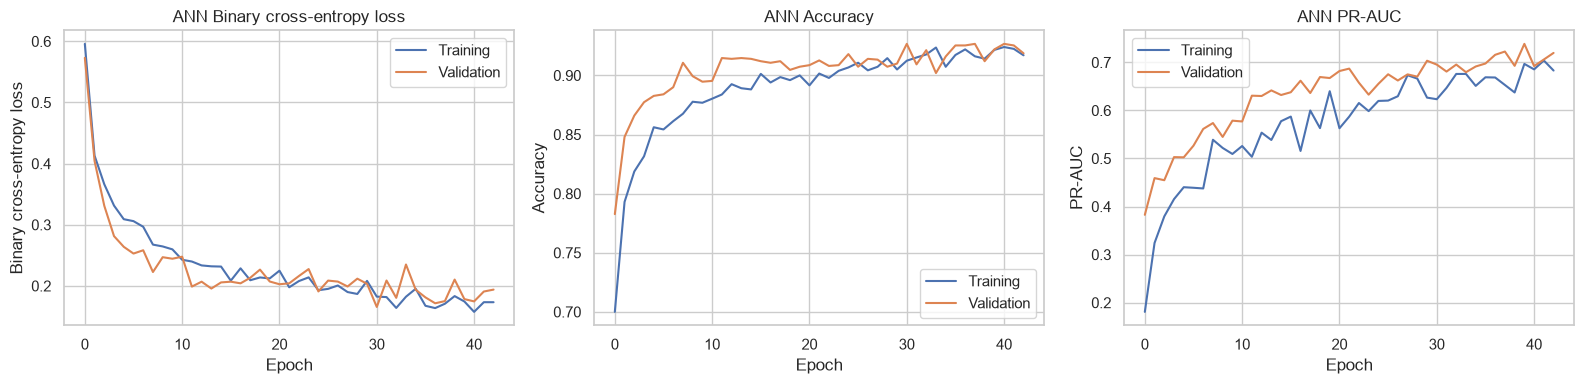

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric, label in zip(axes, ['loss', 'accuracy', 'pr_auc'],
                              ['Binary cross-entropy loss', 'Accuracy', 'PR-AUC']):
    ax.plot(history.history[metric], label='Training')
    ax.plot(history.history['val_' + metric], label='Validation')
    ax.set_title('ANN ' + label)
    ax.set_xlabel('Epoch')
    ax.set_ylabel(label)
    ax.legend()
plt.tight_layout()
plt.show()

### 18.3 Select ANN threshold using validation data

A threshold of 0.5 is not necessarily best for an imbalanced classification problem. As with the ML model, we maximize F1 on validation data only.

ANN validation-derived threshold: 0.8850
ANN validation F1: 0.6981
ANN validation PR-AUC: 0.7168


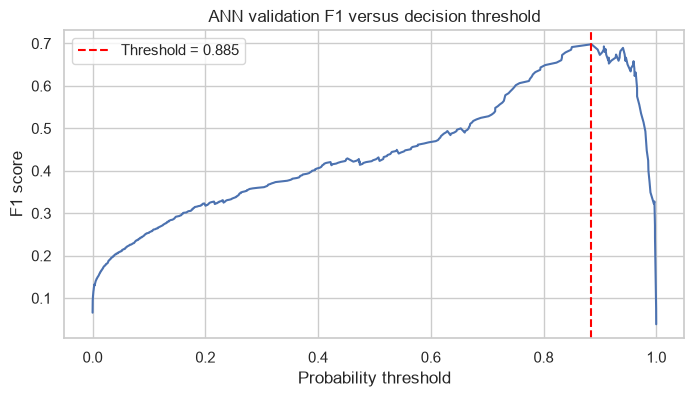

In [22]:
ann_val_prob = ann_model.predict(X_val_ann, verbose=0).ravel()
ann_precision, ann_recall, ann_thresholds = precision_recall_curve(y_val, ann_val_prob)
ann_f1_curve = (2 * ann_precision[:-1] * ann_recall[:-1] /
                (ann_precision[:-1] + ann_recall[:-1] + 1e-12))
ann_best_index = int(np.argmax(ann_f1_curve))
ann_threshold = float(ann_thresholds[ann_best_index])
print(f'ANN validation-derived threshold: {ann_threshold:.4f}')
print(f'ANN validation F1: {ann_f1_curve[ann_best_index]:.4f}')
print(f'ANN validation PR-AUC: {average_precision_score(y_val, ann_val_prob):.4f}')

plt.figure(figsize=(8, 4))
plt.plot(ann_thresholds, ann_f1_curve)
plt.axvline(ann_threshold, linestyle='--', color='red', label=f'Threshold = {ann_threshold:.3f}')
plt.title('ANN validation F1 versus decision threshold')
plt.xlabel('Probability threshold')
plt.ylabel('F1 score')
plt.legend()
plt.show()

The ANN decision threshold was optimized using the validation dataset to maximize the F1-score. The selected threshold was 0.8850, with a validation F1-score of 0.6981. This threshold was subsequently applied to the held-out test dataset without further adjustment.

### 18.4 ANN final held-out test evaluation

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
ANN (Deep Learning),0.9787,0.6508,0.8039,0.7193,0.9811,0.798


ANN classification report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1449
           1       0.65      0.80      0.72        51

    accuracy                           0.98      1500
   macro avg       0.82      0.89      0.85      1500
weighted avg       0.98      0.98      0.98      1500



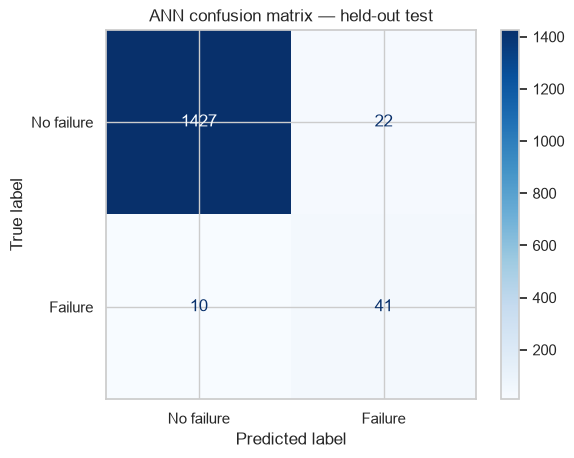

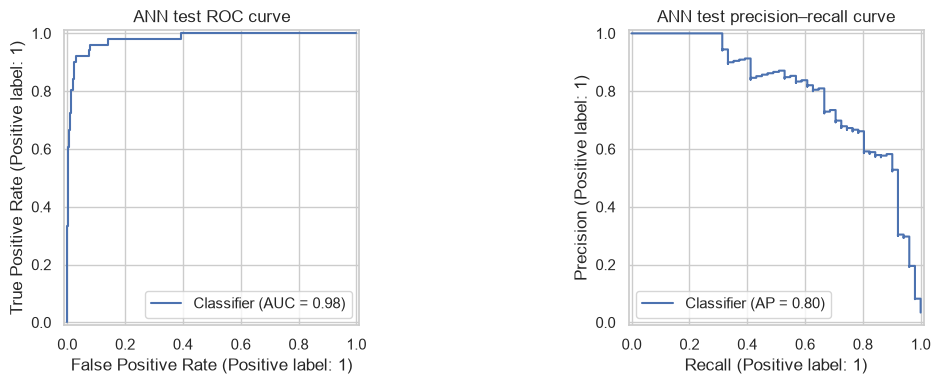

In [23]:
ann_test_prob = ann_model.predict(X_test_ann, verbose=0).ravel()
ann_test_pred = (ann_test_prob >= ann_threshold).astype(int)
ann_metrics = {
    'Accuracy': accuracy_score(y_test, ann_test_pred),
    'Precision': precision_score(y_test, ann_test_pred, zero_division=0),
    'Recall': recall_score(y_test, ann_test_pred, zero_division=0),
    'F1': f1_score(y_test, ann_test_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, ann_test_prob),
    'PR-AUC': average_precision_score(y_test, ann_test_prob)
}
display(pd.DataFrame([ann_metrics], index=['ANN (Deep Learning)']).round(4))
print('ANN classification report:')
print(classification_report(y_test, ann_test_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_test, ann_test_pred, display_labels=['No failure', 'Failure'], cmap='Blues'
)
plt.title('ANN confusion matrix — held-out test')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_test, ann_test_prob, ax=axes[0])
PrecisionRecallDisplay.from_predictions(y_test, ann_test_prob, ax=axes[1])
axes[0].set_title('ANN test ROC curve')
axes[1].set_title('ANN test precision–recall curve')
plt.tight_layout()
plt.show()

### 18.5 Machine Learning versus Deep Learning — final comparison

The table uses actual test results calculated when you run the notebook. F1 and PR-AUC are particularly relevant because machine failures are uncommon. **Do not choose or retune the model using the test set.** The existing Streamlit application continues to use the previously selected ML model.

Held-out test performance comparison:


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Gradient Boosting (Machine Learning),0.9900,0.8333,0.8824,0.8571,0.9754,0.9207
ANN (Deep Learning),0.9787,0.6508,0.8039,0.7193,0.9811,0.7980


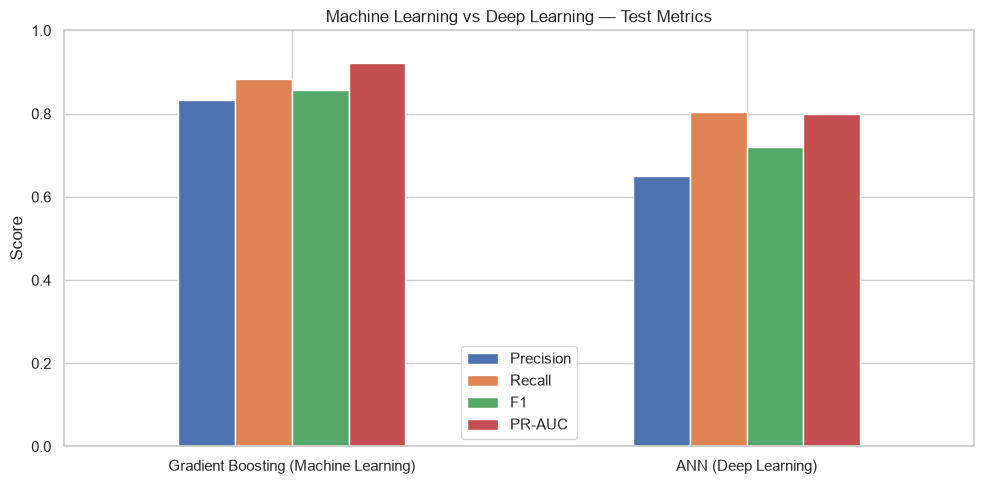

Streamlit model remains: Gradient Boosting
No model-comparison CSV files have been generated.


In [28]:
comparison_df = pd.DataFrame(
    [final_metrics, ann_metrics],
    index=[best_name + ' (Machine Learning)', 'ANN (Deep Learning)']
)
print('Held-out test performance comparison:')
display(comparison_df.round(4))
comparison_df[['Precision', 'Recall', 'F1', 'PR-AUC']].plot(
    kind='bar', figsize=(10, 5), ylim=(0, 1), rot=0
)
plt.title('Machine Learning vs Deep Learning — Test Metrics')
plt.ylabel('Score')
plt.tight_layout()
plt.show()

print('Streamlit model remains:', best_name)
print('No model-comparison CSV files have been generated.')

**Model Selection Interpretation**

The Gradient Boosting model achieved an F1-score of 0.8571 and PR-AUC of 0.9207, compared with the ANN's F1-score of 0.7193 and PR-AUC of 0.7980. Although the ANN obtained a slightly higher ROC-AUC, Gradient Boosting demonstrated better precision and recall for machine failure detection. Therefore, Gradient Boosting is retained as the final deployment model.

The final model was originally selected using cross-validation and validation performance, rather than the test results. The held-out test results provide a comparison of the models' generalization performance.

### 18.6 Optional: Save the ANN separately

The existing Streamlit app loads `machine_failure_detection_model.joblib` and is **not** changed by the ANN training. To preserve the ANN for future deployment, uncomment the lines below. The ANN also needs the fitted `ann_preprocess` and `ann_threshold` to make predictions on raw machine readings.

In [26]:
# Optional ANN artifacts (not needed for existing Streamlit app):
# ann_model.save('machine_failure_ann.keras')
# joblib.dump({'preprocess': ann_preprocess,
#              'threshold': ann_threshold,
#              'feature_columns': X.columns.tolist()},
#             'machine_failure_ann_preprocessing.joblib')
print('ANN training and evaluation complete. Optional ANN saving is disabled.')

ANN training and evaluation complete. Optional ANN saving is disabled.


## 19. Discussion and Conclusion

### 19.1 Discussion

This project developed and evaluated Machine Learning and Deep Learning models to predict machine failures using the AI4I 2020 Predictive Maintenance Dataset.

The Gradient Boosting classifier achieved an accuracy of **99.00%**, precision of **83.33%**, recall of **88.24%**, F1-score of **85.71%**, ROC-AUC of **97.54%**, and PR-AUC of **92.07%** on the held-out test dataset.

The Artificial Neural Network (ANN) achieved an accuracy of **97.87%**, precision of **65.08%**, recall of **80.39%**, F1-score of **71.93%**, ROC-AUC of **98.11%**, and PR-AUC of **79.80%**.

Although the ANN achieved a slightly higher ROC-AUC, Gradient Boosting performed better on precision, recall, F1-score, and PR-AUC. Therefore, Gradient Boosting was selected as the final prediction model.

The Gradient Boosting model correctly identified **45 out of 51 machine failures**, with 6 missed failures and 9 false alarms. In comparison, the ANN correctly identified 41 failures, with 10 missed failures and 22 false alarms.

Permutation feature importance analysis identified mechanical power proxy, tool wear, rotational speed, and temperature difference as influential predictors.

### 19.2 Conclusion

The project demonstrates that Machine Learning and Deep Learning techniques can be used to predict machine failures from operational sensor measurements.

The results show that the Gradient Boosting classifier outperformed the ANN on the main failure-detection metrics for this dataset. The selected model was saved for integration into a Streamlit-based prediction application.

The system can serve as a prototype for predictive maintenance decision support. However, the AI4I 2020 dataset is synthetic, and additional validation using real industrial data would be necessary before practical deployment.

### 19.3 Future Scope

- Evaluate the models using real-time industrial sensor data.
- Explore additional Machine Learning and Deep Learning architectures.
- Incorporate equipment-specific maintenance history.
- Develop a monitoring dashboard with failure alerts.
- Validate model performance on data collected from different machines and operating environments.